# Linda — Landgebruik Vlaanderen (toestand 2025) — Raw Store

Exploration view of the Bandstack's second **Source**: actual land use of
the Flemish Region, one state year, **raw only** — the Aligned Source does
not exist yet (align is a later step).

- **Scope**: latest version **2025 (v3)**, one layer
  (`lu_landgebruik_vlaa_2025_v3`) — one band whose cell *values* are
  categorical **class codes 1–19**
- **Raw Store**: `data/raw/linda/`, fetched and verified by the pipeline
  code (`bandstack.sources.linda.fetch_raw`); the legend is verified
  against the publisher's live SLD style at every fetch
- **Raw native grid**: EPSG:31370 (Belgian Lambert 72), 10 m cells — the
  same CRS as the project grids, and the 10 m **master grid** shares
  Linda's lattice, so loading Linda is a pure clip (no resampling ever)
- **Bounding**: the raw store is the **full published raster** — VPO
  trimmed the 2025 extent to the Flemish Region bbox, which publishes
  *less* than our padded fetch window, so nothing is cut and no mask is
  applied at fetch time; the Study Area mask is applied per grid in the
  statistics and plots below
- **Vintage**: the platform serves no `Last-Modified`/ETag on the
  version-pinned filename, so the Provenance Record pins the download's
  **sha256** as the distribution vintage

In [1]:
import json
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from rasterio.windows import from_bounds
from shapely.geometry import box

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from bandstack.grid import GridSpec, from_preset, study_area_mask
from bandstack.sources.linda import (
    CLASSES,
    LAYER,
    NODATA,
    PUBLISHED_BOUNDS,
    RAW_DIR,
    STATE_YEAR,
    fetch_raw,
)

GISCO_DIR = ROOT / "data" / "raw" / "gisco"
NUTS_ID = "BE2"

# Idempotent fetch (the pipeline entry for Linda until align exists):
# verifies the legend against the live SLD, downloads the published raster
# once, runs the fetch gate, and (re)writes the Provenance Record.
master = from_preset("lambert72", res=10)
written = fetch_raw(master)

RAW_TIF = RAW_DIR / f"{LAYER}.tif"
RAW_META = RAW_DIR / "_metadata.json"
with rasterio.open(RAW_TIF) as src:
    RAW_GRID = GridSpec(crs=src.crs, transform=src.transform, width=src.width, height=src.height)
    LU = src.read(1)
record = json.loads(RAW_META.read_text())

print(f"state year {STATE_YEAR}, {len(CLASSES)} classes; layers written this run: {written}")
print(
    f"raw grid: {RAW_GRID.crs.to_string()}, {RAW_GRID.res:g} m, {RAW_GRID.width}×{RAW_GRID.height}"
)
print(f"raw extent: {RAW_GRID.bounds}")
assert tuple(round(v, 6) for v in RAW_GRID.bounds) == tuple(PUBLISHED_BOUNDS)

legend verified against live SLD: 19 classes
raw window ≈23700×9200 px of the published 23700×9200 (whole published raster; padded window clamped to what the source publishes)
gate passed: 1 mask group(s), sizes [1]; every mask certified against a live second read
raw store ready (0 written, 1 verified)
state year 2025, 19 classes; layers written this run: []
raw grid: EPSG:31370, 10 m, 23700×9200
raw extent: (22000.0, 153000.0, 259000.0, 245000.0)


## Study Area polygon

`BE2` = **Flemish Region** (Brussels is its own NUTS region `BE1` and
excluded). Linda's native CRS *is* the project CRS, so the polygon does
not move between grids here — the interesting geometry is instead how the
**published raster extent** (trimmed to the Flemish Region bbox in the
2025 state) sits inside the **master grid** rectangle: the raw rectangle
stops 1–6 km short of the grid on the west, east and south sides. The
lattice check below is the reason Linda can later be loaded as a pure
clip: both origins sit on the same 10 m lattice.

master grid: (21000.0, 152000.0, 260000.0, 245000.0) (23900×9300)
published offset from master origin: -100 cols, +0 rows (integers -> shared lattice)


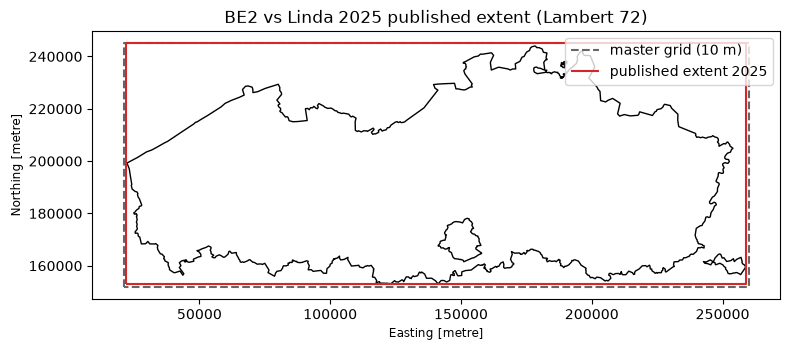

In [2]:
be2 = gpd.read_file(GISCO_DIR / "be2_flemish_region_4326.geojson").to_crs(RAW_GRID.crs)
grid_rect = gpd.GeoDataFrame(geometry=[box(*master.bounds)], crs=master.crs)
pub_rect = gpd.GeoDataFrame(geometry=[box(*RAW_GRID.bounds)], crs=RAW_GRID.crs)

dx = (master.transform.c - RAW_GRID.transform.c) / RAW_GRID.res
dy = (RAW_GRID.transform.f - master.transform.f) / RAW_GRID.res
print(f"master grid: {master.bounds} ({master.width}×{master.height})")
print(
    f"published offset from master origin: {dx:+.0f} cols, {dy:+.0f} rows "
    f"(integers -> shared lattice)"
)
assert float(dx).is_integer() and float(dy).is_integer()

fig, ax = plt.subplots(figsize=(8, 8))
grid_rect.boundary.plot(ax=ax, color="0.4", linestyle="--", label="master grid (10 m)")
pub_rect.boundary.plot(ax=ax, color="tab:red", label="published extent 2025")
be2.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1)
ax.legend()
ax.set_title(f"{NUTS_ID} vs Linda 2025 published extent (Lambert 72)")
plt.tight_layout()
plt.show()

## The store

The fetch is owned by the pipeline code (`fetch_raw`): one whole-file
download of the published GeoTIFF per run (the platform serves no Range
requests, so windowed reads are impossible; the WCS endpoint is broken),
streamed to a run-local temporary file that both the fetch and the gate's
live second read use. The class codes are asserted against the transcribed
legend, and the download's sha256 is recorded as the distribution
vintage. Cross-checks below: the stored file against the Provenance
Record, and the window-wide valid fraction against the publisher's own
statistics.

In [3]:
valid = LU != NODATA
inside = study_area_mask(RAW_GRID)

layer_rec = record["layers"][0]
side = {
    "layer name": layer_rec["name"] == LAYER,
    "window bounds == file bounds": [round(v, 3) for v in layer_rec["window_bounds_l72"]]
    == [round(v, 3) for v in RAW_GRID.bounds],
    "valid_frac_window reproduces": abs(layer_rec["valid_frac_window"] - valid.mean()) < 1e-9,
    "valid_frac_inside reproduces": abs(
        layer_rec["valid_frac_inside"] - valid[inside].sum() / inside.sum()
    )
    < 1e-9,
    "inventory == one layer": record["layer_inventory"] == [LAYER],
    "no decode factors": record["decode_factors"] == {},
    "vintage is a sha256": len(record["distribution"]["file_last_modified"]) == 64,
}
for k, ok in side.items():
    print(f"[{'PASS' if ok else 'FAIL'}] {k}")
assert all(side.values())

print(
    f"valid window fraction {valid.mean():.4f} (publisher statistics on the published file: 0.6228)"
)

[PASS] layer name
[PASS] window bounds == file bounds
[PASS] valid_frac_window reproduces
[PASS] valid_frac_inside reproduces
[PASS] inventory == one layer
[PASS] no decode factors
[PASS] vintage is a sha256
valid window fraction 0.6249 (publisher statistics on the published file: 0.6228)


## Classes

The 19 published classes, their share of the Study Area's classified
cells, and the same inside the full raw rectangle (which contains sea,
Zeeland, Wallonia and Brussels — land where Linda publishes nothing by
design).

observed codes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19] -> all in legend: True


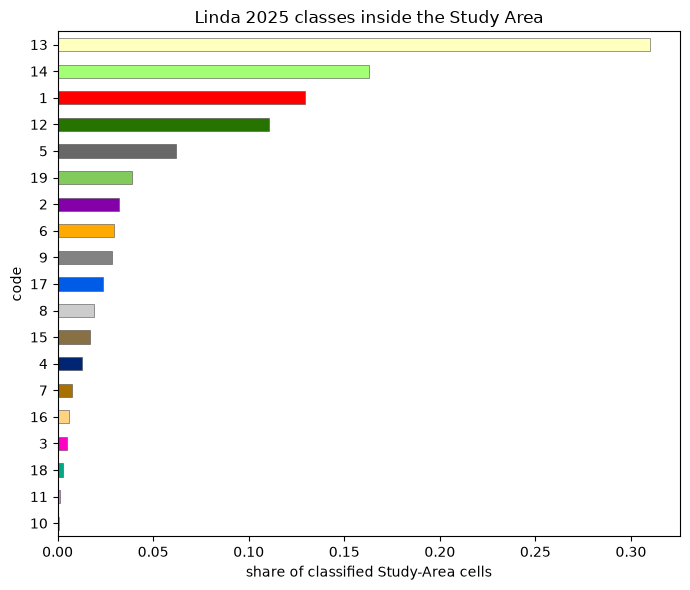

,label,color,share_inside,share_rectangle,area_km2_inside
code,,,,,
13,Akker,#ffffbe,31.02%,30.95%,"4,213"
14,Grasland in landbouwgebruik,#a3ff73,16.30%,16.27%,"2,214"
1,Huizen en tuinen,#ff0000,12.97%,12.93%,"1,761"
12,Bos,#267300,11.04%,11.02%,"1,499"
5,Transportinfrastructuur,#686868,6.19%,6.18%,841
19,Overige graslanden,#82ca5b,3.90%,3.89%,530
2,Industrie,#8400a8,3.19%,3.19%,434
6,Recreatie,#ffaa00,2.97%,2.96%,404
9,Overige onbebouwde terreinen,#828282,2.83%,2.83%,385


In [10]:
observed = set(np.unique(LU).tolist()) - {NODATA}
print("observed codes:", sorted(observed), "-> all in legend:", observed <= set(CLASSES))

counts_in = np.bincount(LU[inside & valid], minlength=max(CLASSES) + 1)[1:]
counts_all = np.bincount(LU[valid], minlength=max(CLASSES) + 1)[1:]

classes_df = pd.DataFrame(
    {
        "label": [CLASSES[c][0] for c in sorted(CLASSES)],
        "color": [CLASSES[c][1] for c in sorted(CLASSES)],
        "share_inside": counts_in / counts_in.sum(),
        "share_rectangle": counts_all / counts_all.sum(),
        "area_km2_inside": counts_in * 1e-4,
    },
    index=pd.Index(sorted(CLASSES), name="code"),
)

plot_df = classes_df.sort_values("share_inside")
ax = plot_df.plot.barh(
    y="share_inside",
    figsize=(7, 6),
    legend=False,
    color=plot_df["color"],
    edgecolor="0.3",
    linewidth=0.4,
)
ax.set_xlabel("share of classified Study-Area cells")
ax.set_title("Linda 2025 classes inside the Study Area")
plt.tight_layout()
plt.show()

classes_df.sort_values("share_inside", ascending=False).style.format(
    {
        "share_inside": "{:.2%}",
        "share_rectangle": "{:.2%}",
        "area_km2_inside": "{:,.0f}",
    }
)

## Map

Overview decimated to ~100 m pixels (colours exactly as published, one
shared legend) and three native 10 m windows: the Antwerp port area
(industry, transport, water), Leuven (compact historic city in a
residential patchwork) and the coast near Oostende (dunes, water,
built-up front).

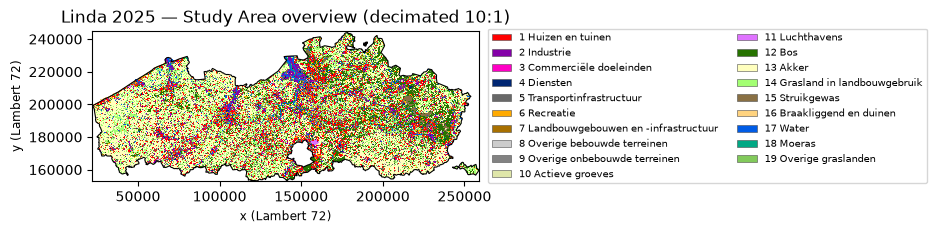

In [5]:
codes = sorted(CLASSES)
cmap = ListedColormap([CLASSES[c][1] for c in codes])
norm = BoundaryNorm([c - 0.5 for c in codes] + [codes[-1] + 0.5], len(codes))
legend = [
    Patch(facecolor=CLASSES[c][1], edgecolor="0.3", linewidth=0.4, label=f"{c} {CLASSES[c][0]}")
    for c in codes
]

with rasterio.open(RAW_TIF) as src:
    overview = src.read(1, out_shape=(RAW_GRID.height // 10, RAW_GRID.width // 10))

w, s, e, n = RAW_GRID.bounds
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.imshow(
    np.ma.masked_equal(overview, NODATA),
    cmap=cmap,
    norm=norm,
    extent=(w, e, s, n),
    interpolation="nearest",
)
be2.boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.set_title("Linda 2025 — Study Area overview (decimated 10:1)")
ax.legend(handles=legend, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=7, ncols=2)
ax.set_xlabel("x (Lambert 72)")
ax.set_ylabel("y (Lambert 72)")
plt.tight_layout()
plt.show()

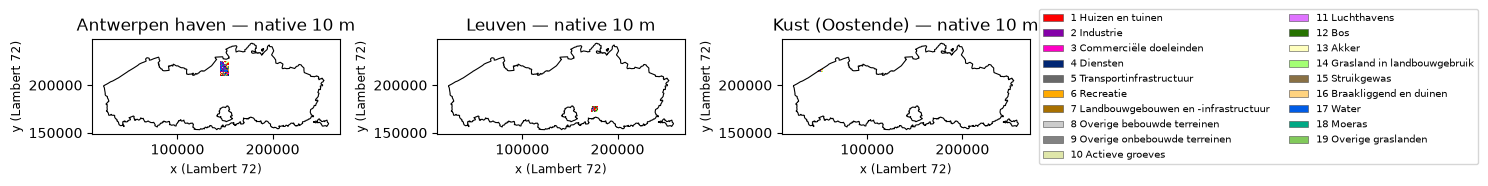

In [6]:
WINDOWS = {
    "Antwerpen haven": (145000.0, 210000.0, 154000.0, 225000.0),
    "Leuven": (172000.0, 172000.0, 180000.0, 178000.0),
    "Kust (Oostende)": (44000.0, 214000.0, 54000.0, 224000.0),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
with rasterio.open(RAW_TIF) as src:
    for ax, (name, (w, s, e, n)) in zip(axes, WINDOWS.items(), strict=True):
        win = from_bounds(w, s, e, n, transform=src.transform).round_offsets().round_lengths()
        arr = src.read(1, window=win)
        tfm = src.window_transform(win)
        ax.imshow(
            np.ma.masked_equal(arr, NODATA),
            cmap=cmap,
            norm=norm,
            extent=(tfm.c, tfm.c + tfm.a * arr.shape[1], tfm.f + tfm.e * arr.shape[0], tfm.f),
            interpolation="nearest",
        )
        be2.boundary.plot(ax=ax, color="black", linewidth=0.8)
        ax.set_title(f"{name} — native 10 m")
        ax.set_xlabel("x (Lambert 72)")
        ax.set_ylabel("y (Lambert 72)")
axes[2].legend(handles=legend, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=7, ncols=2)
plt.tight_layout()
plt.show()

## Nodata anatomy

`−9999` has three distinct meanings over the project grids:

1. **Outside the Flemish Region, inside the published rectangle** — sea,
   Zeeland, Wallonia, and the Brussels hole: the bulk of the published
   nodata, by design;
2. **Inside the Study Area but unclassified** — measured at fetch time as
   0.16 % of Study-Area cells: where do these sit, and do they hug the
   border (likely `all_touched` edge cells along coast and rivers) or
   form interior patches?
3. **Master-grid cells outside the published extent** — the west, east and
   south margins of the padded window; they carry no Linda data at all.
   They lie outside the Study Area mask, so no Study-Area cell is
   affected.

1. outside region, inside rectangle: 81,572,471 cells (8,157 km²)
2. inside region, unclassified:      223,136 cells (22.3 km²) = 0.164% of Study-Area cells
3. master-grid cells outside published extent: 4,230,000 (423 km²), of which inside Study Area: 0
   of which border-adjacent: 56,099 (25.1%)
   unclassified fill of 1-km blocks: max 17%, blocks > 50%: 0 -> speckle, not holes


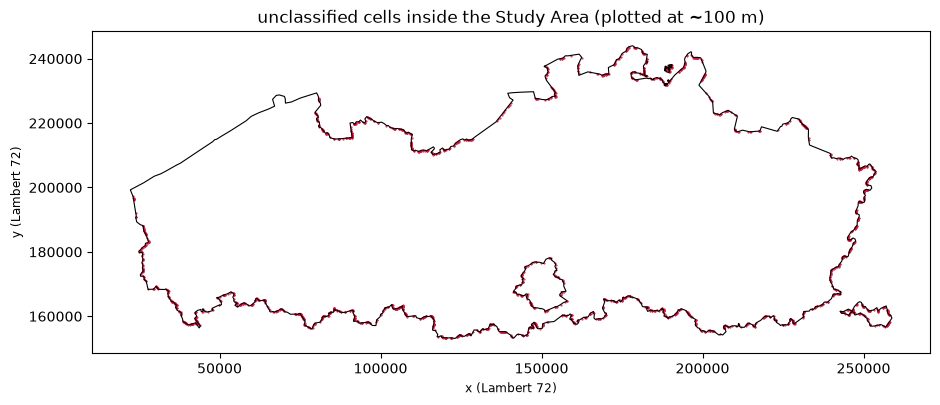

In [7]:
nodata_inside = inside & ~valid
print(
    f"1. outside region, inside rectangle: {(~valid & ~inside).sum():,} cells "
    f"({(~valid & ~inside).sum() * 1e-4:,.0f} km²)"
)
print(
    f"2. inside region, unclassified:      {nodata_inside.sum():,} cells "
    f"({nodata_inside.sum() * 1e-4:,.1f} km²) = {1 - valid[inside].sum() / inside.sum():.3%} "
    f"of Study-Area cells"
)

mg_mask = study_area_mask(master)
mg_cov = np.zeros(mg_mask.shape, dtype=bool)
r0 = int((RAW_GRID.transform.f - master.transform.f) / 10)
c0 = int((RAW_GRID.transform.c - master.transform.c) / 10)
mg_cov[r0 : r0 + RAW_GRID.height, c0 : c0 + RAW_GRID.width] = True
print(
    f"3. master-grid cells outside published extent: {(~mg_cov).sum():,} "
    f"({(~mg_cov).sum() * 1e-4:,.0f} km²), of which inside Study Area: {(mg_mask & ~mg_cov).sum()}"
)

# Do the unclassified inside-region cells hug the border? A cell is
# border-adjacent if any of its 8 neighbours is published-nodata outside
# the region (edge wrap-around is negligible at this scale).
outside = ~inside
border_adj = np.zeros_like(nodata_inside)
for dr in (-1, 0, 1):
    for dc in (-1, 0, 1):
        if dr == 0 and dc == 0:
            continue
        border_adj |= np.roll(np.roll(outside, dr, axis=0), dc, axis=1)
n_border = (nodata_inside & border_adj).sum()
print(f"   of which border-adjacent: {n_border:,} ({n_border / nodata_inside.sum():.1%})")

# Are the interior ones contiguous patches or diffuse speckle? Fill fraction
# per 1-km block: a hole (quarry, military domain) would fill a block;
# speckle never does.
blocks = (
    nodata_inside.reshape(RAW_GRID.height // 100, 100, RAW_GRID.width // 100, 100).sum(axis=(1, 3))
    / 10000
)
kind = "speckle, not holes" if (blocks <= 0.5).all() else "contiguous patches present"
print(
    f"   unclassified fill of 1-km blocks: max {blocks.max():.0%}, "
    f"blocks > 50%: {(blocks > 0.5).sum()} -> {kind}"
)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
spots = nodata_inside[::10, ::10]
ys, xs = np.nonzero(spots)
ax.scatter(
    RAW_GRID.transform.c + (xs + 0.5) * 100,
    RAW_GRID.transform.f - (ys + 0.5) * 100,
    s=1,
    c="crimson",
    marker=".",
)
be2.boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.set_title("unclassified cells inside the Study Area (plotted at ~100 m)")
ax.set_xlabel("x (Lambert 72)")
ax.set_ylabel("y (Lambert 72)")
plt.tight_layout()
plt.show()

## Takeaways

- The raw store is the **full published raster** (23 700 × 9 200 at 10 m,
  EPSG:31370), fetched by one verified whole-file download whose sha256 is
  the recorded vintage — the platform serves no file date.
- The **master grid shares Linda's lattice** (integer offset), so the
  later Aligned Source is a pure clip — no resampling anywhere in Linda's
  chain.
- Linda 2025 classifies **99.84 % of Study-Area cells**. The remaining
  0.16 %: a quarter hugs the region border, the rest is diffuse speckle
  (no km² block exceeds ~17 % fill — no interior holes) — unlike
  SoilGrids, whose published gaps exclude ~18 % of cells from the
  modelling domain.
- Distance-to-land-use and class-fraction predictors will be derived from
  this one state year; land use *outside* Flanders (the Brussels
  surroundings and across the borders) is unknowable from this Source —
  the documented border-knowledge limitation.